# FreshBasket Loyalty Churn — EDA
Reproducible workbook inspection, missingness and duplicate checks. 
This notebook does not modify source data or churn labels.

In [19]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if ROOT.name.lower() != 'tailwyndz_churn_prediction' and ROOT.parent.name.lower() == 'tailwyndz_churn_prediction': ROOT = ROOT.parent
WORKBOOK = ROOT / 'data' / 'raw' / 'FreshBasket_Loyalty_Churn_Dataset.xlsx'
assert WORKBOOK.exists(), f'Workbook not found: {WORKBOOK}'
xls = pd.ExcelFile(WORKBOOK)
print('Sheets:', xls.sheet_names)
tables = {s: pd.read_excel(WORKBOOK, sheet_name=s) for s in xls.sheet_names}


Sheets: ['Glossary', 'fb Customer Profile', 'fb Monthly Activity', 'fb Churn Label', 'Data Dictionary']


In [20]:
for name, df in tables.items():
    print('\\n', name, 'shape=', df.shape, 'exact duplicates=', int(df.duplicated().sum()))
    display(df.head())
    display(df.isna().sum().sort_values(ascending=False).head(20).to_frame('missing_count'))


\n Glossary shape= (10, 4) exact duplicates= 2


,Unnamed: 0,Unnamed: 1,Unnamed: 2,FreshBasket Loyalty: Customer Churn Prediction
0,The data contained in this file includes 18 mo...,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN
2,Three tables are provided:,NaN,NaN,NaN
3,- fb Customer Profile: one row per loyalty me...,NaN,NaN,NaN
4,- fb Monthly Activity: one row per customer p...,NaN,NaN,NaN


,missing_count
Unnamed: 1,10
Unnamed: 2,10
FreshBasket Loyalty: Customer Churn Prediction,10
Unnamed: 0,3


\n fb Customer Profile shape= (2609, 10) exact duplicates= 8


,Unnamed: 0,Unnamed: 1,Unnamed: 2,FreshBasket Loyalty: Customer Churn Prediction,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,CUSTOMER_ID,SIGNUP_DATE,AGE,GENDER,CITY,MEMBERSHIP_TIER,MARKETING_OPT_IN,PREFERRED_STORE_ID,PREFERRED_CATEGORY,HOME_STORE_PRICE_TIER
1,500001,2022-08-17 00:00:00,36,F,Madison,Silver,1,140,Frozen Foods,Value
2,500002,2023-06-24 00:00:00,37,F,Spokane,Silver,0,119,Beverages,Mainstream
3,500003,2021-03-31 00:00:00,53,NaN,Tulsa,Gold,0,119,Frozen Foods,Mainstream
4,500004,2021-07-08 00:00:00,52,F,Spokane,Gold,1,106,Snacks,Upscale


...

,Unnamed: 0,Unnamed: 1,Unnamed: 2,FreshBasket Loyalty: Customer Churn Prediction,Unnamed: 4,Unnamed: 5
0,CUSTOMER_ID,OBSERVATION_END_DATE,LAST_PURCHASE_DATE,MONTHS_OBSERVED,INSUFFICIENT_HISTORY_FLAG,CHURNED
1,500001,2024-06-30 00:00:00,2024-06-01 00:00:00,18,0,0
2,500002,2024-06-30 00:00:00,2024-06-01 00:00:00,12,0,0
3,500003,2024-06-30 00:00:00,2024-06-01 00:00:00,18,0,0
4,500004,2024-06-30 00:00:00,2024-06-01 00:00:00,18,0,0


,missing_count
Unnamed: 2,120
Unnamed: 0,0
Unnamed: 1,0
FreshBasket Loyalty: Customer Churn Prediction,0
Unnamed: 4,0
Unnamed: 5,0


\n Data Dictionary shape= (29, 4) exact duplicates= 0


,Unnamed: 0,Unnamed: 1,Unnamed: 2,FreshBasket Loyalty: Customer Churn Prediction
0,TABLE,COLUMN,DESCRIPTION,NaN
1,fb Customer Profile,CUSTOMER_ID,Unique loyalty member identifier,NaN
2,fb Customer Profile,SIGNUP_DATE,Date the member joined the loyalty program,NaN
3,fb Customer Profile,AGE,Member age in years (some missing),NaN
4,fb Customer Profile,GENDER,F / M / Other (some missing),NaN


,missing_count
FreshBasket Loyalty: Customer Churn Prediction,29
Unnamed: 0,0
Unnamed: 1,0
Unnamed: 2,0


In [21]:
for name, df in tables.items():
    if 'CHURNED' in df.columns:
        print('Label table:', name)
        display(df['CHURNED'].value_counts(dropna=False).rename_axis('CHURNED').to_frame('rows'))
        ax = df['CHURNED'].value_counts().sort_index().plot(kind='bar', rot=0)
        ax.set_title('Churn label distribution'); ax.set_xlabel('CHURNED'); ax.set_ylabel('Rows')
        plt.tight_layout(); plt.show()


## Interpretation guardrails
- Confirm the target definition before modelling.
- Keep April–June 2024 activity out of predictors if that is the target window.
- Missing activity months do not automatically mean zero transactions.
- Preserve conflicting customer-month records pending clarification.
- Use future-time validation after label and feature timing are verified.

In [22]:
churn_raw = pd.read_excel(
    workbook,
    sheet_name="fb Churn Label",
    header=None
)

display(churn_raw.head(15))

,0,1,2,3,4,5
0,NaN,NaN,NaN,FreshBasket Loyalty: Customer Churn Prediction,NaN,NaN
1,CUSTOMER_ID,OBSERVATION_END_DATE,LAST_PURCHASE_DATE,MONTHS_OBSERVED,INSUFFICIENT_HISTORY_FLAG,CHURNED
2,500001,2024-06-30 00:00:00,2024-06-01 00:00:00,18,0,0
3,500002,2024-06-30 00:00:00,2024-06-01 00:00:00,12,0,0
4,500003,2024-06-30 00:00:00,2024-06-01 00:00:00,18,0,0
5,500004,2024-06-30 00:00:00,2024-06-01 00:00:00,18,0,0
6,500005,2024-06-30 00:00:00,NaN,1,1,0
7,500006,2024-06-30 00:00:00,2024-06-01 00:00:00,18,0,0
8,500007,2024-06-30 00:00:00,2024-06-01 00:00:00,18,0,0
9,500008,2024-06-30 00:00:00,2024-06-01 00:00:00,18,0,0


In [23]:
churn = pd.read_excel(
    workbook,
    sheet_name="fb Churn Label",
    header=1
)

churn = churn.dropna(how="all")
churn.columns = churn.columns.astype(str).str.strip()

print("Churn columns:", churn.columns.tolist())
display(churn.head())

print("\nChurn label counts:")
display(churn["CHURNED"].value_counts(dropna=False).sort_index())

Churn columns: ['CUSTOMER_ID', 'OBSERVATION_END_DATE', 'LAST_PURCHASE_DATE', 'MONTHS_OBSERVED', 'INSUFFICIENT_HISTORY_FLAG', 'CHURNED']


,CUSTOMER_ID,OBSERVATION_END_DATE,LAST_PURCHASE_DATE,MONTHS_OBSERVED,INSUFFICIENT_HISTORY_FLAG,CHURNED
0,500001,2024-06-30,2024-06-01,18,0,0
1,500002,2024-06-30,2024-06-01,12,0,0
2,500003,2024-06-30,2024-06-01,18,0,0
3,500004,2024-06-30,2024-06-01,18,0,0
4,500005,2024-06-30,NaT,1,1,0



Churn label counts:


CHURNED
0    1784
1     821
Name: count, dtype: int64

In [24]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image, Markdown

# Find the project root
cwd = Path.cwd()
PROJECT_ROOT = next(
    (
        folder for folder in [cwd, *cwd.parents]
        if (folder / "reports" / "phase3").exists()
        and (folder / "data").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root not found. Run this notebook from inside "
        r"C:\Tailwyndz_Churn_Prediction"
    )

REPORT_DIR = PROJECT_ROOT / "reports" / "phase3"
RAW_DIR = PROJECT_ROOT / "data" / "raw"

print("Project root:", PROJECT_ROOT)
print("Phase 3 reports:", REPORT_DIR)

# Load the original workbook
workbook = RAW_DIR / "FreshBasket_Loyalty_Churn_Dataset.xlsx"


sheets = {
    "fb Customer Profile": pd.read_excel(
        workbook, sheet_name="fb Customer Profile", header=1
    ),
    "fb Monthly Activity": pd.read_excel(
        workbook, sheet_name="fb Monthly Activity", header=1
    ),
    "fb Churn Label": pd.read_excel(
        workbook, sheet_name="fb Churn Label", header=1
    ),
}

profile = sheets["fb Customer Profile"].copy()
activity = sheets["fb Monthly Activity"].copy()
churn = sheets["fb Churn Label"].copy()

for df in (profile, activity, churn):
    df.columns = df.columns.astype(str).str.strip()

print("Profile columns:", profile.columns.tolist())
print("Activity columns:", activity.columns.tolist())
print("Churn columns:", churn.columns.tolist())


display(profile.head())
display(activity.head())
display(churn.head())


Project root: C:\Tailwyndz_Churn_Prediction
Phase 3 reports: C:\Tailwyndz_Churn_Prediction\reports\phase3
Profile columns: ['CUSTOMER_ID', 'SIGNUP_DATE', 'AGE', 'GENDER', 'CITY', 'MEMBERSHIP_TIER', 'MARKETING_OPT_IN', 'PREFERRED_STORE_ID', 'PREFERRED_CATEGORY', 'HOME_STORE_PRICE_TIER']
Activity columns: ['CUSTOMER_ID', 'MONTH', 'TRANSACTIONS', 'TOTAL_SPEND', 'AVG_BASKET_VALUE', 'DISTINCT_CATEGORIES', 'PROMO_TXN_PCT', 'APP_SESSIONS', 'EMAILS_OPENED', 'COUPONS_REDEEMED', 'SUPPORT_TICKETS', 'COMPLAINT_FLAG']
Churn columns: ['CUSTOMER_ID', 'OBSERVATION_END_DATE', 'LAST_PURCHASE_DATE', 'MONTHS_OBSERVED', 'INSUFFICIENT_HISTORY_FLAG', 'CHURNED']


,CUSTOMER_ID,SIGNUP_DATE,AGE,GENDER,CITY,MEMBERSHIP_TIER,MARKETING_OPT_IN,PREFERRED_STORE_ID,PREFERRED_CATEGORY,HOME_STORE_PRICE_TIER
0,500001,2022-08-17,36.0,F,Madison,Silver,1,140,Frozen Foods,Value
1,500002,2023-06-24,37.0,F,Spokane,Silver,0,119,Beverages,Mainstream
2,500003,2021-03-31,53.0,NaN,Tulsa,Gold,0,119,Frozen Foods,Mainstream
3,500004,2021-07-08,52.0,F,Spokane,Gold,1,106,Snacks,Upscale
4,500005,2023-09-28,19.0,F,Portland,Gold,1,118,Bakery,Mainstream


,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE,DISTINCT_CATEGORIES,PROMO_TXN_PCT,APP_SESSIONS,EMAILS_OPENED,COUPONS_REDEEMED,SUPPORT_TICKETS,COMPLAINT_FLAG
0,501855,2023-03-01,5,150.01,30.00,4,0.04,3,0,1,0,0
1,501803,2024-04-01,12,325.77,27.15,3,0.12,1,2,0,0,0
2,501889,2024-05-01,4,165.54,41.38,4,0.60,4,1,0,0,0
3,502005,2023-03-01,2,130.82,65.41,2,0.31,4,1,1,0,0
4,500568,2024-01-01,1,15.86,15.86,0,0.39,0,0,1,1,1


,CUSTOMER_ID,OBSERVATION_END_DATE,LAST_PURCHASE_DATE,MONTHS_OBSERVED,INSUFFICIENT_HISTORY_FLAG,CHURNED
0,500001,2024-06-30,2024-06-01,18,0,0
1,500002,2024-06-30,2024-06-01,12,0,0
2,500003,2024-06-30,2024-06-01,18,0,0
3,500004,2024-06-30,2024-06-01,18,0,0
4,500005,2024-06-30,NaT,1,1,0


In [25]:

frames = {
    "Customer Profile": profile,
    "Monthly Activity": activity,
    "Churn Labels": churn
}

for name, df in frames.items():
    print(f"\n{'=' * 60}\n{name}\n{'=' * 60}")
    print("Shape:", df.shape)
    print("Exact duplicate rows:", int(df.duplicated().sum()))

    overview = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(2),
        "unique_values": df.nunique(dropna=True)
    })
    display(overview)



Customer Profile
Shape: (2608, 10)
Exact duplicate rows: 8


,dtype,missing_count,missing_percent,unique_values
CUSTOMER_ID,int64,0,0.00,2600
SIGNUP_DATE,datetime64[ns],0,0.00,1027
AGE,float64,78,2.99,57
GENDER,object,52,1.99,3
CITY,object,0,0.00,40
MEMBERSHIP_TIER,object,0,0.00,12
MARKETING_OPT_IN,int64,0,0.00,2
PREFERRED_STORE_ID,int64,0,0.00,40
PREFERRED_CATEGORY,object,0,0.00,8
HOME_STORE_PRICE_TIER,object,130,4.98,3



Monthly Activity
Shape: (28073, 12)
Exact duplicate rows: 58


,dtype,missing_count,missing_percent,unique_values
CUSTOMER_ID,int64,0,0.0,2594
MONTH,datetime64[ns],0,0.0,18
TRANSACTIONS,int64,0,0.0,20
TOTAL_SPEND,float64,0,0.0,17164
AVG_BASKET_VALUE,float64,0,0.0,4085
DISTINCT_CATEGORIES,int64,0,0.0,9
PROMO_TXN_PCT,float64,0,0.0,92
APP_SESSIONS,int64,0,0.0,14
EMAILS_OPENED,int64,0,0.0,9
COUPONS_REDEEMED,int64,0,0.0,8



Churn Labels
Shape: (2605, 6)
Exact duplicate rows: 5


,dtype,missing_count,missing_percent,unique_values
CUSTOMER_ID,int64,0,0.00,2600
OBSERVATION_END_DATE,datetime64[ns],0,0.00,1
LAST_PURCHASE_DATE,datetime64[ns],120,4.61,18
MONTHS_OBSERVED,int64,0,0.00,18
INSUFFICIENT_HISTORY_FLAG,int64,0,0.00,2
CHURNED,int64,0,0.00,2


In [26]:

print("ACTIVITY COLUMNS")
print(activity.columns.tolist())

# Identify columns using their names
lower_cols = {str(c).lower().strip(): c for c in activity.columns}

def find_col(possible_names, columns):
    for name in possible_names:
        if name in columns:
            return columns[name]
    return None

spend_col = find_col(
    ["total_spend", "spend", "monthly_spend", "total_amount", "amount_spent"],
    lower_cols
)
transactions_col = find_col(
    ["total_transactions", "transactions", "transaction_count", "num_transactions"],
    lower_cols
)
customer_col = find_col(
    ["customer_id", "customerid", "customer id"],
    lower_cols
)
month_col = find_col(
    ["month", "activity_month", "year_month", "month_id"],
    lower_cols
)

print("Detected spend column:", spend_col)
print("Detected transaction column:", transactions_col)
print("Detected customer column:", customer_col)
print("Detected month column:", month_col)

if spend_col:
    spend = pd.to_numeric(activity[spend_col], errors="coerce")
    print("\nNegative spend rows:", int((spend < 0).sum()))
    print("Zero spend rows:", int((spend == 0).sum()))
    display(activity.loc[spend < 0].head(10))

if transactions_col:
    transactions = pd.to_numeric(
        activity[transactions_col], errors="coerce"
    )
    print("\nZero-transaction rows:", int((transactions == 0).sum()))

    if spend_col:
        print(
            "Positive spend but zero transactions:",
            int(((spend > 0) & (transactions == 0)).sum())
        )
        print(
            "Zero spend but positive transactions:",
            int(((spend == 0) & (transactions > 0)).sum())
        )

if customer_col and month_col:
    duplicate_customer_month = activity.duplicated(
        subset=[customer_col, month_col], keep=False
    )
    print(
        "\nRows belonging to repeated customer-month keys:",
        int(duplicate_customer_month.sum())
    )
    display(activity.loc[duplicate_customer_month].head(20))


ACTIVITY COLUMNS
['CUSTOMER_ID', 'MONTH', 'TRANSACTIONS', 'TOTAL_SPEND', 'AVG_BASKET_VALUE', 'DISTINCT_CATEGORIES', 'PROMO_TXN_PCT', 'APP_SESSIONS', 'EMAILS_OPENED', 'COUPONS_REDEEMED', 'SUPPORT_TICKETS', 'COMPLAINT_FLAG']
Detected spend column: TOTAL_SPEND
Detected transaction column: TRANSACTIONS
Detected customer column: CUSTOMER_ID
Detected month column: MONTH

Negative spend rows: 24
Zero spend rows: 2355


,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE,DISTINCT_CATEGORIES,PROMO_TXN_PCT,APP_SESSIONS,EMAILS_OPENED,COUPONS_REDEEMED,SUPPORT_TICKETS,COMPLAINT_FLAG
731,501082,2023-09-01,10,-226.93,22.69,4,0.09,5,0,0,1,0
772,500973,2024-02-01,1,-31.05,31.05,2,0.69,0,2,1,0,0
2765,501679,2024-03-01,7,-249.21,35.60,3,0.20,4,0,1,0,0
4478,500160,2023-01-01,2,-89.01,44.50,4,0.55,2,0,1,0,0
4646,501401,2023-05-01,4,-67.01,16.75,5,0.12,5,2,0,0,0
5344,501769,2023-03-01,1,-52.38,52.38,3,0.42,3,2,0,0,0
6119,501344,2023-12-01,7,-237.96,33.99,2,0.22,3,4,0,0,0
7028,501222,2023-04-01,5,-101.39,20.28,1,0.29,0,0,1,0,0
7572,502227,2024-02-01,5,-196.53,39.31,5,0.47,1,1,1,0,0
7964,501597,2023-08-01,3,-138.85,46.28,4,0.38,2,1,0,0,0



Zero-transaction rows: 2335
Positive spend but zero transactions: 0
Zero spend but positive transactions: 20

Rows belonging to repeated customer-month keys: 120


,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE,DISTINCT_CATEGORIES,PROMO_TXN_PCT,APP_SESSIONS,EMAILS_OPENED,COUPONS_REDEEMED,SUPPORT_TICKETS,COMPLAINT_FLAG
121,500143,2023-08-01,5,162.69,32.54,2,0.14,3,2,1,0,0
169,500387,2023-04-01,0,0.00,0.00,1,0.00,5,1,1,0,0
389,502137,2024-06-01,8,177.35,22.17,3,0.26,5,0,1,0,0
450,500047,2023-02-01,7,207.53,29.65,4,0.21,1,1,1,1,0
979,501771,2023-05-01,5,162.65,32.53,2,0.08,5,1,0,0,0
1218,501525,2023-06-01,2,62.05,31.02,2,0.26,0,0,0,1,0
1244,501960,2023-12-01,5,160.56,32.11,2,0.22,0,1,1,0,0
1287,501302,2024-05-01,1,23.95,23.95,2,0.27,4,3,1,0,0
1403,502137,2024-06-01,8,177.35,22.17,3,0.26,5,0,1,0,0
1744,501607,2024-04-01,12,290.82,24.24,4,0.22,3,0,2,0,0


In [27]:

print("POTENTIAL TEXT CASING INCONSISTENCIES")

for name, df in frames.items():
    text_columns = df.select_dtypes(include=["object", "string"]).columns
    print(f"\n{name}")

    found = False
    for col in text_columns:
        values = df[col].dropna().astype(str)
        inconsistent = values[
            values.ne(values.str.strip())
            | values.ne(values.str.lower())
        ]
        if not inconsistent.empty:
            found = True
            print(f"\nColumn: {col}")
            display(inconsistent.value_counts().head(10).rename("count"))

    if not found:
        print("No obvious whitespace/lowercase inconsistencies detected.")


POTENTIAL TEXT CASING INCONSISTENCIES

Customer Profile

Column: GENDER


GENDER
F        1370
M        1090
Other      96
Name: count, dtype: int64


Column: CITY


CITY
Tulsa        287
Raleigh      274
Columbus     259
Austin       254
Denver       250
Madison      245
Spokane      243
Boise        239
Nashville    228
Portland     225
Name: count, dtype: int64


Column: MEMBERSHIP_TIER


...


Column: PREFERRED_CATEGORY


PREFERRED_CATEGORY
Frozen Foods     356
Household        352
Bakery           338
Snacks           335
Beverages        322
Personal Care    309
Dairy            307
Produce          289
Name: count, dtype: int64


Column: HOME_STORE_PRICE_TIER


HOME_STORE_PRICE_TIER
Mainstream    1162
Value          898
Upscale        418
Name: count, dtype: int64


Monthly Activity
No obvious whitespace/lowercase inconsistencies detected.

Churn Labels
No obvious whitespace/lowercase inconsistencies detected.


In [28]:

if customer_col and month_col:
    month_data = activity[[customer_col, month_col]].dropna().copy()

    # Convert month values to calendar months where possible
    month_data["_month"] = pd.to_datetime(
        month_data[month_col].astype(str), errors="coerce"
    ).dt.to_period("M")

    if month_data["_month"].notna().any():
        rows = []
        for customer_id, group in month_data.dropna(
            subset=["_month"]
        ).groupby(customer_col):
            observed = set(group["_month"])
            if not observed:
                continue

            all_months = pd.period_range(
                min(observed), max(observed), freq="M"
            )
            missing = sorted(set(all_months) - observed)
            rows.append({
                "customer_id": customer_id,
                "observed_months": len(observed),
                "missing_months": len(missing),
                "missing_month_list": ", ".join(map(str, missing[:12]))
            })

        missing_months = pd.DataFrame(rows)
        if not missing_months.empty:
            print("Customers with missing months:",
                  int((missing_months["missing_months"] > 0).sum()))
            display(
                missing_months.sort_values(
                    "missing_months", ascending=False
                ).head(20)
            )
    else:
        print(
            "Month values were not parsed as dates. Inspect the month "
            "column format before calculating missing months."
        )
else:
    print("Could not identify customer/month columns; inspect Cell 6 output.")


Customers with missing months: 769


,customer_id,observed_months,missing_months,missing_month_list
2336,502342,14,4,"2023-02, 2023-03, 2023-06, 2024-02"
2271,502277,14,4,"2023-05, 2023-08, 2023-10, 2024-05"
1329,501333,14,4,"2023-02, 2023-08, 2023-12, 2024-04"
1341,501345,14,4,"2023-06, 2023-09, 2023-11, 2024-05"
1146,501149,11,4,"2023-06, 2023-11, 2024-01, 2024-03"
780,500782,15,3,"2023-03, 2023-07, 2024-04"
349,500350,15,3,"2023-05, 2023-07, 2024-01"
2453,502459,15,3,"2023-06, 2023-07, 2024-05"
367,500368,15,3,"2023-05, 2023-08, 2024-02"
287,500288,15,3,"2023-03, 2024-02, 2024-05"


Q1: 58.77
Q3: 188.15
IQR: 129.38
Lower bound: -135.30
Upper bound: 382.22
Outlier rows: 669


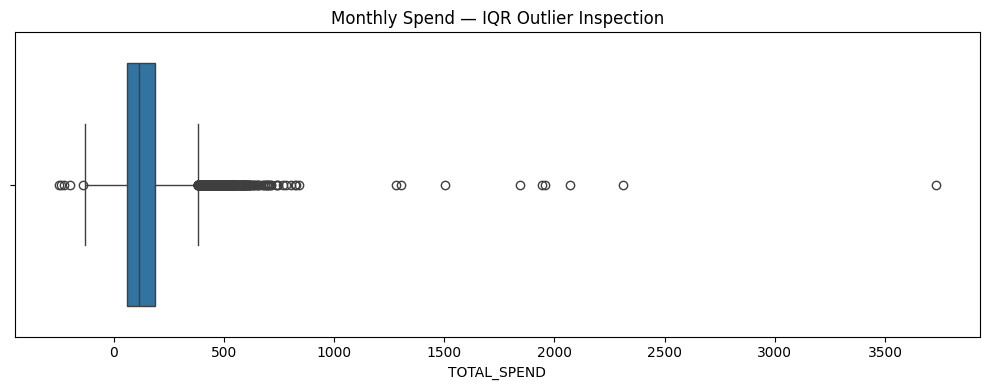

,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE,DISTINCT_CATEGORIES,PROMO_TXN_PCT,APP_SESSIONS,EMAILS_OPENED,COUPONS_REDEEMED,SUPPORT_TICKETS,COMPLAINT_FLAG
52,500046,2023-01-01,10,448.89,44.89,2,0.11,3,3,1,0,0
94,500605,2023-04-01,8,403.93,50.49,4,0.32,1,1,0,0,0
139,500958,2023-08-01,10,506.69,50.67,3,0.14,0,0,1,0,0
272,502273,2024-01-01,11,457.63,41.60,3,0.64,1,0,0,0,0
348,500870,2023-05-01,11,408.63,37.15,6,0.22,3,0,2,0,0
405,502057,2024-05-01,8,498.60,62.32,4,0.25,0,1,1,0,0
415,502409,2024-01-01,10,594.41,59.44,4,0.03,2,3,1,1,1
433,500332,2024-05-01,7,427.98,61.14,3,0.41,1,1,1,0,0
435,502162,2024-06-01,10,386.11,38.61,3,0.74,3,1,0,0,0
443,501131,2023-07-01,10,400.66,40.07,7,0.15,4,0,0,0,0


In [29]:

if spend_col:
    spend = pd.to_numeric(activity[spend_col], errors="coerce").dropna()

    q1 = spend.quantile(0.25)
    q3 = spend.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = activity.loc[
        pd.to_numeric(activity[spend_col], errors="coerce").lt(lower_bound)
        | pd.to_numeric(activity[spend_col], errors="coerce").gt(upper_bound)
    ]

    print(f"Q1: {q1:.2f}")
    print(f"Q3: {q3:.2f}")
    print(f"IQR: {iqr:.2f}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Outlier rows: {len(outliers)}")

    plt.figure(figsize=(10, 4))
    sns.boxplot(x=spend)
    plt.title("Monthly Spend — IQR Outlier Inspection")
    plt.xlabel(spend_col)
    plt.tight_layout()
    plt.show()

    # Outliers are flagged for review, not automatically removed.
    display(outliers.head(10))


Churn columns: ['CUSTOMER_ID', 'OBSERVATION_END_DATE', 'LAST_PURCHASE_DATE', 'MONTHS_OBSERVED', 'INSUFFICIENT_HISTORY_FLAG', 'CHURNED']
Dataset shape: (2605, 6)

Churn label counts:


,Customer count
CHURNED,
0,1784
1,821



Churn label percentages:


,Percentage
CHURNED,
0,68.48
1,31.52


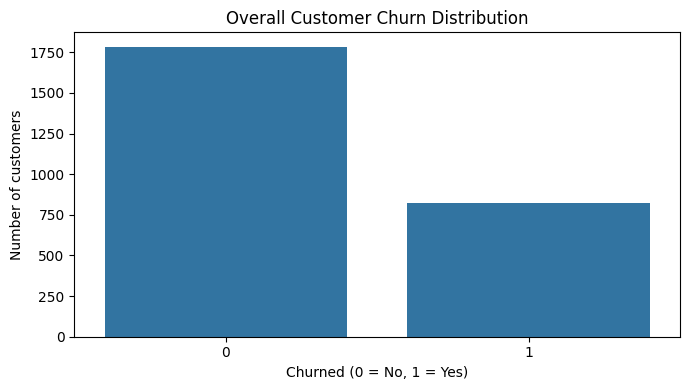

In [30]:

# Load the churn sheet using the correct header row
churn = pd.read_excel(
    workbook,
    sheet_name="fb Churn Label",
    header=1
)

churn.columns = churn.columns.astype(str).str.strip()
churn = churn.dropna(how="all")

print("Churn columns:", churn.columns.tolist())
print("Dataset shape:", churn.shape)

# Convert churn label to numeric
churn["CHURNED"] = pd.to_numeric(churn["CHURNED"], errors="coerce")

print("\nChurn label counts:")
display(
    churn["CHURNED"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("CHURNED")
    .to_frame("Customer count")
)

print("\nChurn label percentages:")
display(
    (churn["CHURNED"].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
    .rename("Percentage")
    .to_frame()
)

plt.figure(figsize=(7, 4))
sns.countplot(data=churn, x="CHURNED")
plt.title("Overall Customer Churn Distribution")
plt.xlabel("Churned (0 = No, 1 = Yes)")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()


In [31]:

# Clean column names
profile.columns = profile.columns.astype(str).str.strip()
churn.columns = churn.columns.astype(str).str.strip()

def find_column(df, candidates):
    lookup = {
        str(col).strip().lower().replace(" ", "_"): col
        for col in df.columns
    }
    for candidate in candidates:
        if candidate in lookup:
            return lookup[candidate]
    return None

profile_id_col = find_column(
    profile, ["customer_id", "customerid", "cust_id", "customer_number"]
)

churn_id_col = find_column(
    churn, ["customer_id", "customerid", "cust_id", "customer_number"]
)

print("Profile customer ID:", profile_id_col)
print("Churn customer ID:", churn_id_col)

if profile_id_col is None or churn_id_col is None:
    print("Could not identify the ID columns. Check Step 1 output.")
else:
    profile[profile_id_col] = pd.to_numeric(
        profile[profile_id_col], errors="coerce"
    )
    churn[churn_id_col] = pd.to_numeric(
        churn[churn_id_col], errors="coerce"
    )

    eligible = churn.copy()

    if "INSUFFICIENT_HISTORY_FLAG" in eligible.columns:
        eligible["INSUFFICIENT_HISTORY_FLAG"] = pd.to_numeric(
            eligible["INSUFFICIENT_HISTORY_FLAG"], errors="coerce"
        )
        eligible = eligible[
            eligible["INSUFFICIENT_HISTORY_FLAG"] == 0
        ]

    eligible["CHURNED"] = pd.to_numeric(
        eligible["CHURNED"], errors="coerce"
    )

    customer_analysis = profile.merge(
        eligible[[churn_id_col, "CHURNED"]].dropna(
            subset=[churn_id_col, "CHURNED"]
        ).drop_duplicates(subset=[churn_id_col]),
        left_on=profile_id_col,
        right_on=churn_id_col,
        how="inner"
    )

    print("Matched eligible customers:", len(customer_analysis))
    display(customer_analysis.head())


Profile customer ID: CUSTOMER_ID
Churn customer ID: CUSTOMER_ID
Matched eligible customers: 2232


,CUSTOMER_ID,SIGNUP_DATE,AGE,GENDER,CITY,MEMBERSHIP_TIER,MARKETING_OPT_IN,PREFERRED_STORE_ID,PREFERRED_CATEGORY,HOME_STORE_PRICE_TIER,CHURNED
0,500001,2022-08-17,36.0,F,Madison,Silver,1,140,Frozen Foods,Value,0
1,500002,2023-06-24,37.0,F,Spokane,Silver,0,119,Beverages,Mainstream,0
2,500003,2021-03-31,53.0,NaN,Tulsa,Gold,0,119,Frozen Foods,Mainstream,0
3,500004,2021-07-08,52.0,F,Spokane,Gold,1,106,Snacks,Upscale,0
4,500006,2022-09-14,44.0,F,Nashville,Silver,0,128,Snacks,Upscale,0


In [32]:
print("PROFILE COLUMNS:")
print(profile.columns.tolist())

print("\nPROFILE FIRST 5 ROWS:")
display(profile.head())

print("\nCHURN COLUMNS:")
print(churn.columns.tolist())

PROFILE COLUMNS:
['CUSTOMER_ID', 'SIGNUP_DATE', 'AGE', 'GENDER', 'CITY', 'MEMBERSHIP_TIER', 'MARKETING_OPT_IN', 'PREFERRED_STORE_ID', 'PREFERRED_CATEGORY', 'HOME_STORE_PRICE_TIER']

PROFILE FIRST 5 ROWS:


,CUSTOMER_ID,SIGNUP_DATE,AGE,GENDER,CITY,MEMBERSHIP_TIER,MARKETING_OPT_IN,PREFERRED_STORE_ID,PREFERRED_CATEGORY,HOME_STORE_PRICE_TIER
0,500001,2022-08-17,36.0,F,Madison,Silver,1,140,Frozen Foods,Value
1,500002,2023-06-24,37.0,F,Spokane,Silver,0,119,Beverages,Mainstream
2,500003,2021-03-31,53.0,NaN,Tulsa,Gold,0,119,Frozen Foods,Mainstream
3,500004,2021-07-08,52.0,F,Spokane,Gold,1,106,Snacks,Upscale
4,500005,2023-09-28,19.0,F,Portland,Gold,1,118,Bakery,Mainstream



CHURN COLUMNS:
['CUSTOMER_ID', 'OBSERVATION_END_DATE', 'LAST_PURCHASE_DATE', 'MONTHS_OBSERVED', 'INSUFFICIENT_HISTORY_FLAG', 'CHURNED']
